In [148]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [149]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
import numpy as np

from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.metrics import confusion_matrix
from imblearn.under_sampling import RandomUnderSampler

from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.utils import df_features_to_numpy, df_target_to_numpy
from src.graficos import plot_confusion_matrix, plot_learning_curves_linear_regression, plot_learning_curves_logistic_regression, plot_comparacion_metricas, plot_feature_importance_regression
from src.splitting import split_estratificado_autor

# Cargo el dataset ya procesado

In [182]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_us_english_primer_filtrado.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

In [151]:
#chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)
#
#chunk_list33 = []
#for chunk in chunks33:
#    chunk_list33.append(chunk)
#
#df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
#print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

## Temporal, sacar cuando este el json ya procesado posta

In [152]:
#TEMPORAL: normalmente estas features ya van a estar agrupadas
from src.features import normalize_format
#Le aplico la funcion para reagrupar:
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

format_group
PAPERBACK    53951
HARDCOVER    22384
EBOOK        17134
UNKNOWN       4281
AUDIO         1657
OTHER          546
COMIC           47
Name: count, dtype: int64


In [153]:
#TEMPORAL: normalmente los generos ya van a estar definidos
from src.features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)

In [154]:
#TEMPORAL: ya va a estar hecho el one hot de estas features
from src.features import multi_binarizer_format, multi_binarizer_genre, one_hot_format
#df = multi_binarizer_format(df) #multi binarizer de format
df = one_hot_format(df)
df = multi_binarizer_genre(df) #multi binarizer de genero

In [155]:
#TEMPORAL: normalmente va a haber que cargar los 3 datasets, ya splitteados
#df_dev, df_test = train_test_split(df, test_size = 0.2, stratify = df["estrellas"], random_state = 42)
#df_train, df_val = train_test_split(df_dev, test_size = 0.2, stratify = df_dev["estrellas"], random_state = 42)

## Preparacion de los datos

# ANALISIS DE AUTOR! PASAR AL NOTEBOOK DE EDA


In [156]:
#Creamos una nueva feature n_authors, que contiene la cantidad de autores de un libro
df.loc[:, "n_authors"] = df["authors"].apply(len)

print("Distribución de cantidad de autores por libro:")
print(f"\n% con 1 solo autor: {(df['n_authors'] == 1).mean():.1%}")
print(f"% con mas de 2 autores: {(df['n_authors'] >= 2).mean():.1%}")
print(f"% con 0 autores: {(df['n_authors'] == 0).mean():.1%}")

#DECISION: elimino los pocos libros que no tienen ningun autor (la lista de diccionarios esta vacia)
df = df[df["authors"].apply(len) > 0]
#comentario para sol: el 0.0% es enganioso, esta redondeado, si imprimis mas decimales va a aparecer 0.00001, ademas, seguro con todo el dataset va a aparecer algun libro mas sin autor

Distribución de cantidad de autores por libro:

% con 1 solo autor: 78.9%
% con mas de 2 autores: 21.1%
% con 0 autores: 0.0%


In [157]:
#Todos los roles que aparecen, con su frecuencia
roles = (df["authors"].explode().apply(lambda x: x["role"]).value_counts())
total_roles = roles.sum()
print("Frecuencia de cada rol:")

for role, count in roles[:20].items():
    if role != "":
        label = role 
    else: 
        label = ""
    print(f"  {label}: {count} ({count/total_roles:.1%})")

Frecuencia de cada rol:
  : 113199 (80.4%)
  Contributor: 5895 (4.2%)
  Illustrator: 4708 (3.3%)
  Editor: 4381 (3.1%)
  Illustrations: 2055 (1.5%)
  Translator: 1774 (1.3%)
  Narrator: 1269 (0.9%)
  Introduction: 819 (0.6%)
  Foreword: 598 (0.4%)
  Artist: 407 (0.3%)
  Translation: 401 (0.3%)
  Writer: 354 (0.3%)
  Creator: 300 (0.2%)
  Text: 283 (0.2%)
  contributor: 280 (0.2%)
  Foreword by: 220 (0.2%)
  editor: 173 (0.1%)
  Photographs: 169 (0.1%)
  Photographer: 159 (0.1%)
  translator: 128 (0.1%)


In [158]:
def primer_tiene_role_vacio(authors_list):
    return authors_list[0]["role"] == ""
df["primer_es_vacio"] = df["authors"].apply(primer_tiene_role_vacio)

print("¿El primer autor de la lista tiene role vacío?")
print(df["primer_es_vacio"].value_counts(normalize=True))

¿El primer autor de la lista tiene role vacío?
primer_es_vacio
True     0.95631
False    0.04369
Name: proportion, dtype: float64


En base a estos analisis, decidio extraer el autor principal de la siguiente manera:
Noto que si el valor de "role" esta vacio (que es la mayoria de los casos), es el autor (en sentido de escritor). En caso de que haya varios, devuelvo el primero, el principal.

In [159]:
def extraer_autor_principal(autores_sin_preprocesar):
    """
    autores_sin preprocesar: [{authorId, role}, {authorid, role})]
    Asumimos que el primer elemento de la lista es el autor principal (orden tipico de Goodreads)
    """
    # Buscar el primero con role vacío; si no hay, usar el primero de la lista
    for dic_autores in autores_sin_preprocesar:
        if dic_autores["role"] == "":
            return dic_autores["author_id"]
    return autores_sin_preprocesar[0]["author_id"]

df["author_id_principal"] = df["authors"].apply(extraer_autor_principal)

# FIN DE ANALISIS DE AUTOR

# SPLITTING ! 
temporal, volar cuando ya tenga el json de sol

In [160]:
df_train, df_val, df_test = split_estratificado_autor(df, test_size=0.15, val_size=0.15)

print(f"Train: {len(df_train)} ({len(df_train)/len(df):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df):.1%})")

#Verificacion: distribución de estrellas en cada split
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize=True).sort_index())

Train: 72431 (72.4%)
Val: 12571 (12.6%)
Test: 14997 (15.0%)

train:
estrellas
0    0.002678
1    0.001312
2    0.008974
3    0.146829
4    0.776228
5    0.063978
Name: proportion, dtype: float64

val:
estrellas
0    0.002625
1    0.001432
2    0.008909
3    0.149391
4    0.775197
5    0.062445
Name: proportion, dtype: float64

test:
estrellas
0    0.002601
1    0.001267
2    0.008802
3    0.150297
4    0.773488
5    0.063546
Name: proportion, dtype: float64


# FIN DE LO TEMPORAL

In [161]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'format_group_AUDIO', 'format_group_COMIC', 'format_group_EBOOK', 'format_group_HARDCOVER', 'format_group_OTHER', 'format_group_PAPERBACK'] + generos #'format_group_UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

## Regresion Lineal con features basicas

In [162]:
modeloBaseRegresionLineal = LinearRegression() 
modeloBaseRegresionLineal.fit(X_train_scaled, y_train_regresion) #Minimiza MSE

y_pred_train_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloBaseRegresionLineal, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloBaseRegresionLineal, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.241028    0.239894
RMSE  0.490946    0.489790
MAE   0.336852    0.336293
R²    0.052922    0.045352


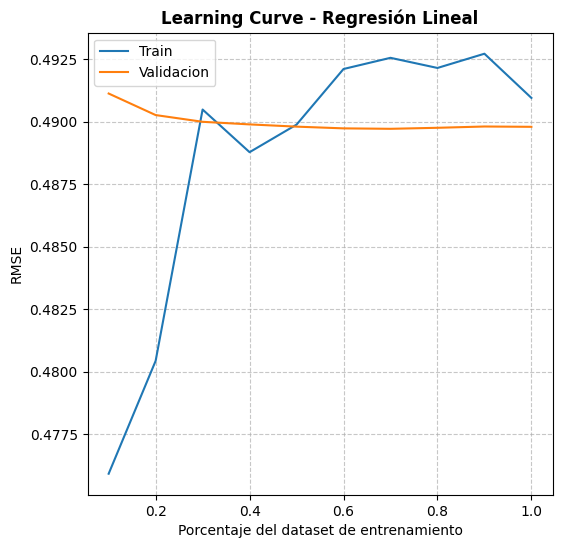

In [163]:
plot_learning_curves_linear_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion)

Analizamos la feature importance:

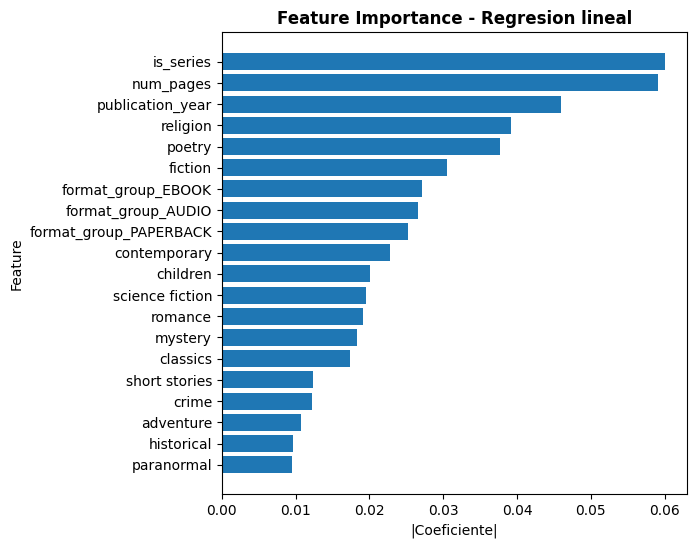

In [165]:
coeficientes_regresion_lineal = pd.DataFrame({"feature": features, "coef": modeloBaseRegresionLineal.coef_})
coeficientes_regresion_lineal["abs_coef"] = np.abs(coeficientes_regresion_lineal["coef"])
coeficientes_regresion_lineal = coeficientes_regresion_lineal.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_lineal, "lineal")

## Regresion Logistica con features basicas

              Train  Validation
Accuracy   0.776325    0.775197
Precision  0.288241    0.195916
Recall     0.167530    0.167448
F1         0.147519    0.147243


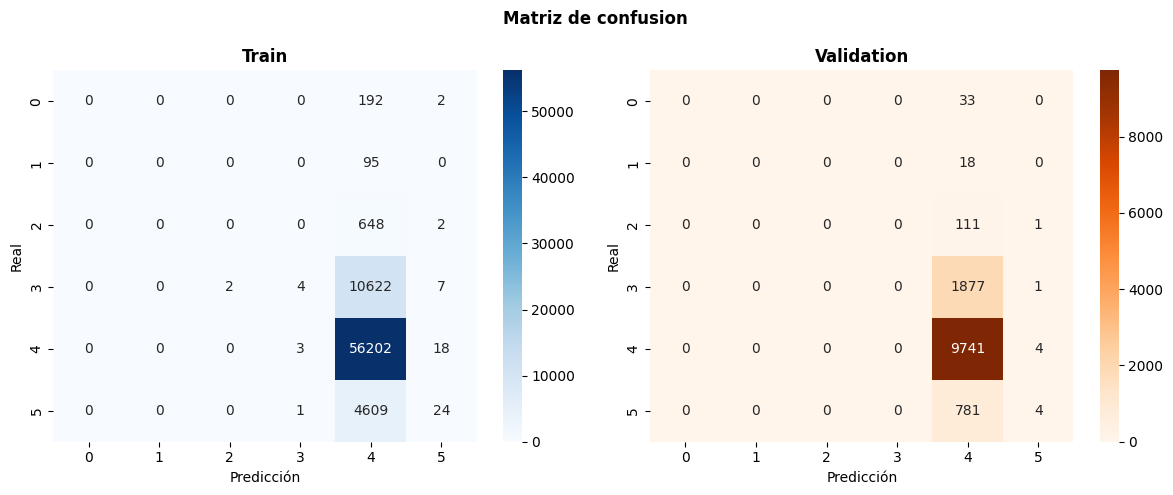

In [166]:
modeloBaseRegresionLogistica = LogisticRegression(max_iter = 1000)
modeloBaseRegresionLogistica.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_val_scaled)

metricas_train_base = evaluar_metricas_clasificacion(y_pred_train_modeloBaseRegresionLogistica, y_train_clasificacion)
metricas_val_base = evaluar_metricas_clasificacion(y_pred_val_modeloBaseRegresionLogistica, y_val_clasificacion)
tabla_metricas_regresion_logistica_base = tabla_metricas(metricas_train_base, metricas_val_base, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_base)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloBaseRegresionLogistica)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloBaseRegresionLogistica)
plot_confusion_matrix(cm_train, cm_val)

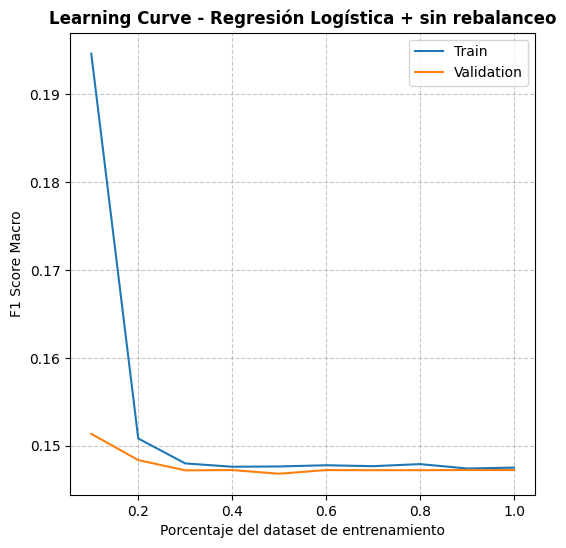

In [167]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "sin rebalanceo")

Analizamos la feature importance:

In [181]:
coeficientes_regresion_log = pd.DataFrame({"feature": features, "coef": modeloBaseRegresionLogistica.coef_})
coeficientes_regresion_log["abs_coef"] = np.abs(coeficientes_regresion_log["coef"])
coeficientes_regresion_log = coeficientes_regresion_log.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log, "Logistica")

ValueError: Per-column arrays must each be 1-dimensional

### Balanceo de clases

El primer balanceo que intento es el predeterminado de scikit learn

              Train  Validation
Accuracy   0.491806    0.491369
Precision  0.225517    0.219365
Recall     0.394993    0.322064
F1         0.213515    0.204893


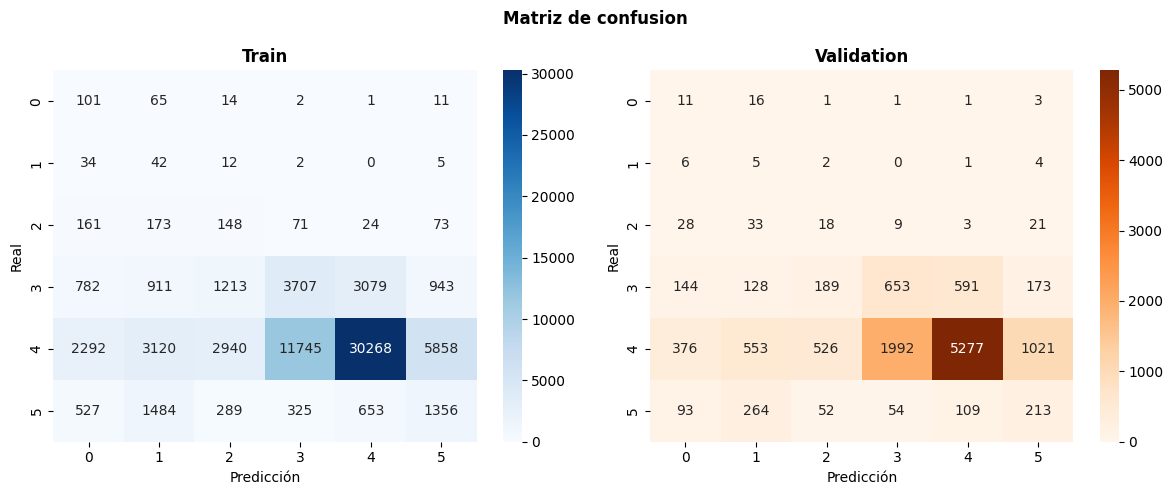

In [169]:
rebalanceo_1 = LogisticRegression(max_iter = 1000, class_weight = "balanced")
rebalanceo_1.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_1 = rebalanceo_1.predict(X_train_scaled)
y_pred_val_rebalanceo_1 = rebalanceo_1.predict(X_val_scaled)

metricas_train_balanced = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_1, y_train_clasificacion)
metricas_val_balanced = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_1, y_val_clasificacion)
tabla_metricas_regresion_logistica_1 = tabla_metricas(metricas_train_balanced, metricas_val_balanced, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_1)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_1)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_1)
plot_confusion_matrix(cm_train, cm_val)

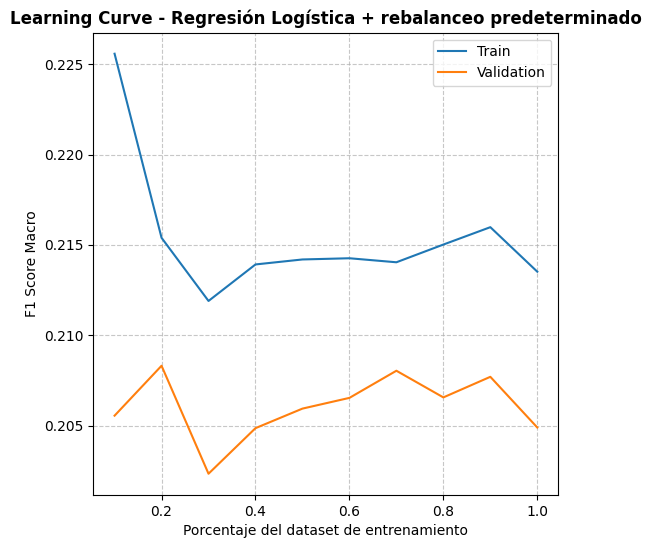

In [170]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "rebalanceo predeterminado", modelo_class_weight = "balanced")

Analizamos la feature importance:

In [180]:
coeficientes_regresion_log_balanced = pd.DataFrame({"feature": features, "coef": rebalanceo_1.coef_})
coeficientes_regresion_log_balanced["abs_coef"] = np.abs(coeficientes_regresion_log_balanced["coef"])
coeficientes_regresion_log_balanced = coeficientes_regresion_log_balanced.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log_balanced, "Logistica + rebalanceo predeterminado")

ValueError: Per-column arrays must each be 1-dimensional

Ahora intento ponerles pesos personalizados

              Train  Validation
Accuracy   0.753448    0.755548
Precision  0.252339    0.238251
Recall     0.220296    0.221599
F1         0.216176    0.214776


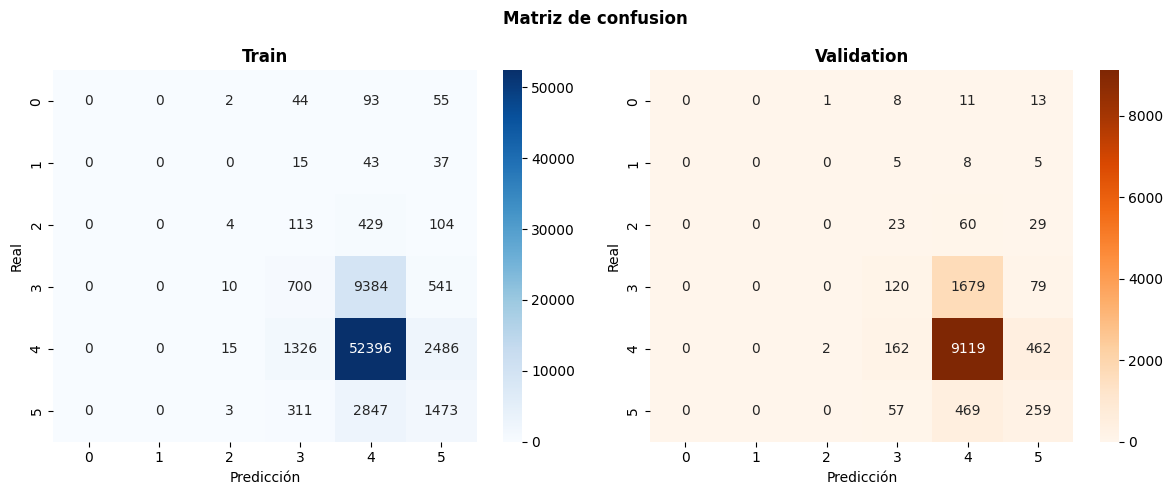

In [172]:
pesos_rlog_3 = {1:10, 2:4, 3:2, 4:1, 5:2} #defino diferentes pesos para dar prioridad a las clases mas minoritarias
rebalanceo_2 = LogisticRegression(max_iter = 1000, class_weight = pesos_rlog_3)
rebalanceo_2.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_2 = rebalanceo_2.predict(X_train_scaled)
y_pred_val_rebalanceo_2 = rebalanceo_2.predict(X_val_scaled)

metricas_train_manual = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_2, y_train_clasificacion)
metricas_val_manual = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_2, y_val_clasificacion)
tabla_metricas_regresion_logistica_2 = tabla_metricas(metricas_train_manual, metricas_val_manual, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_2)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_2)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_2)
plot_confusion_matrix(cm_train, cm_val)

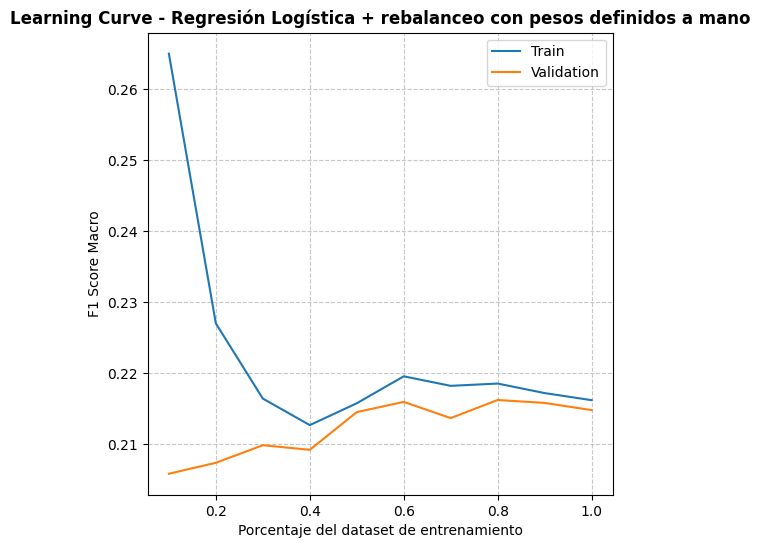

In [173]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "rebalanceo con pesos definidos a mano", modelo_class_weight = pesos_rlog_3)

Analizamos la feature importance:

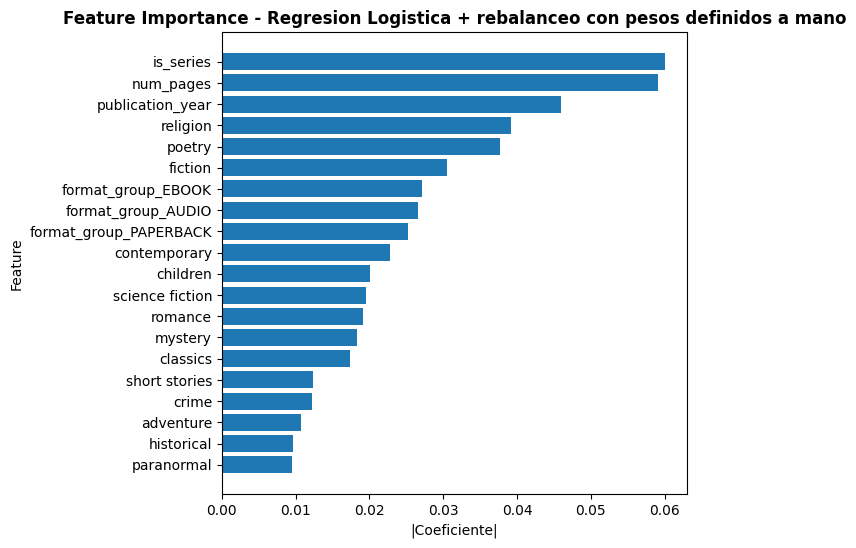

In [174]:
coeficientes_regresion_log_personalizado = pd.DataFrame({"feature": features, "coef": rebalanceo_2.coef_})
coeficientes_regresion_log_personalizado["abs_coef"] = np.abs(coeficientes_regresion_log_personalizado["coef"])
coeficientes_regresion_log_personalizado = coeficientes_regresion_log_personalizado.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log_personalizado, "Logistica + rebalanceo con pesos definidos a mano")

              Train  Validation
Accuracy   0.652317    0.648238
Precision  0.250038    0.243093
Recall     0.283839    0.272688
F1         0.256805    0.249362


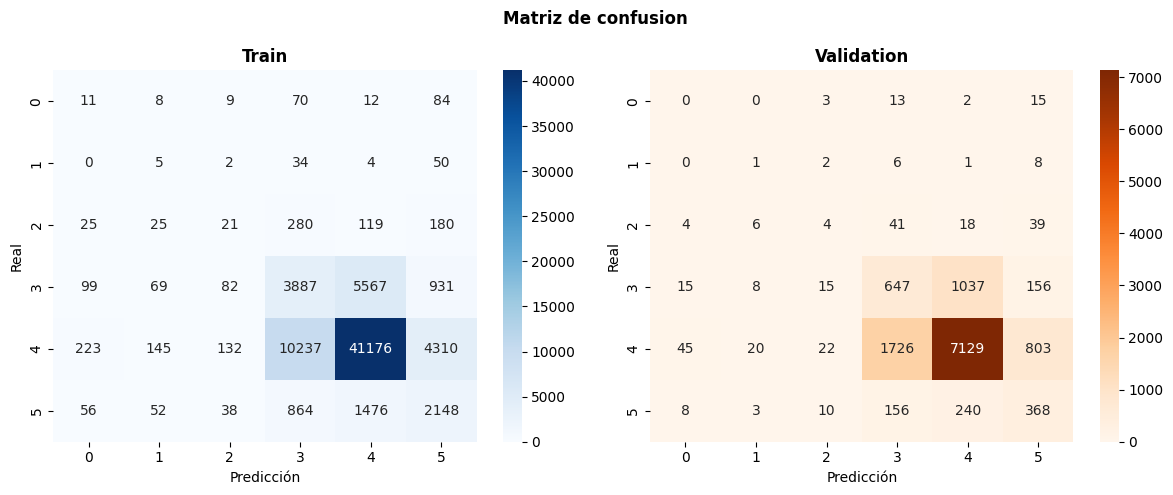

In [175]:
cant_datos_deseada = {4: 30000} #TODO: numero hardcodeado, adaptar al dataset q use desp
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_res, y_res = undersampling.fit_resample(X_train, y_train_clasificacion) 

scaler = StandardScaler()
X_res_scaled = scaler.fit_transform(X_res)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

pesos_rlog_4 = {0:12, 1:30, 2:7, 3:2, 4:1, 5:2} #TODO: ir tuneando
rebalanceo_3 = LogisticRegression(class_weight = pesos_rlog_4, max_iter = 1000)
rebalanceo_3.fit(X_res_scaled, y_res)

y_pred_train_rebalanceo_3 = rebalanceo_3.predict(X_train_scaled)
y_pred_val_rebalanceo_3 = rebalanceo_3.predict(X_val_scaled)

metricas_train_undersampling = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_3, y_train_clasificacion)
metricas_val_undersampling = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_3, y_val_clasificacion)
tabla_metricas_regresion_logistica_3 = tabla_metricas(metricas_train_undersampling, metricas_val_undersampling, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_3)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_3)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_3)
plot_confusion_matrix(cm_train, cm_val)

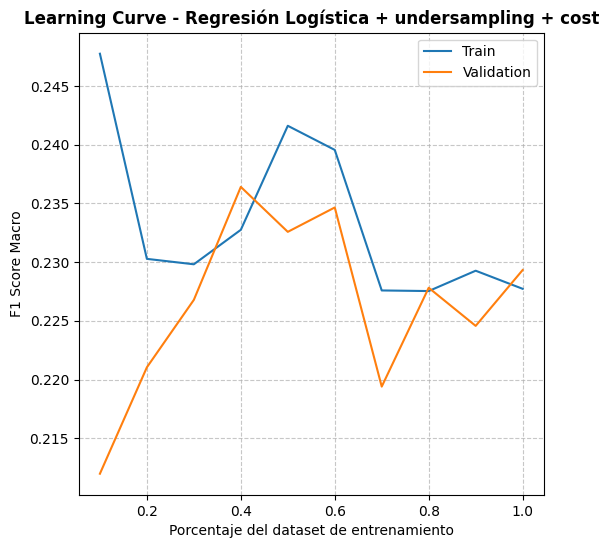

In [176]:
plot_learning_curves_logistic_regression(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, "undersampling + cost", modelo_class_weight = pesos_rlog_4)

Analizamos la feature importance:

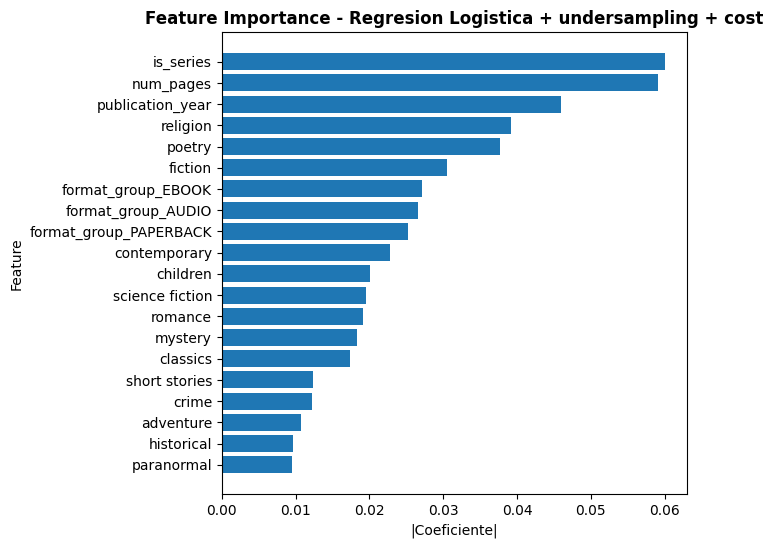

In [177]:
coeficientes_regresion_log_undersampling = pd.DataFrame({"feature": features, "coef": rebalanceo_3.coef_})
coeficientes_regresion_log_undersampling["abs_coef"] = np.abs(coeficientes_regresion_log_undersampling["coef"])
coeficientes_regresion_log_undersampling = coeficientes_regresion_log_undersampling.sort_values("abs_coef", ascending = False)
plot_feature_importance_regression(coeficientes_regresion_log_undersampling, "Logistica + undersampling + cost")

In [178]:
print("Comparacion de tablas de metricas segun los diferentes rebalanceos")

print("\nModelo sin rebalanceo")
print(tabla_metricas_regresion_logistica_base)

print("\nModelo con rebalanceo predeterminado")
print(tabla_metricas_regresion_logistica_1)

print("\nModelo con rebalanceo con pesos definidos a mano")
print(tabla_metricas_regresion_logistica_2)

print("\nModelo con undersampling + cost")
print(tabla_metricas_regresion_logistica_3)

Comparacion de tablas de metricas segun los diferentes rebalanceos

Modelo sin rebalanceo
              Train  Validation
Accuracy   0.776325    0.775197
Precision  0.288241    0.195916
Recall     0.167530    0.167448
F1         0.147519    0.147243

Modelo con rebalanceo predeterminado
              Train  Validation
Accuracy   0.491806    0.491369
Precision  0.225517    0.219365
Recall     0.394993    0.322064
F1         0.213515    0.204893

Modelo con rebalanceo con pesos definidos a mano
              Train  Validation
Accuracy   0.753448    0.755548
Precision  0.252339    0.238251
Recall     0.220296    0.221599
F1         0.216176    0.214776

Modelo con undersampling + cost
              Train  Validation
Accuracy   0.652317    0.648238
Precision  0.250038    0.243093
Recall     0.283839    0.272688
F1         0.256805    0.249362


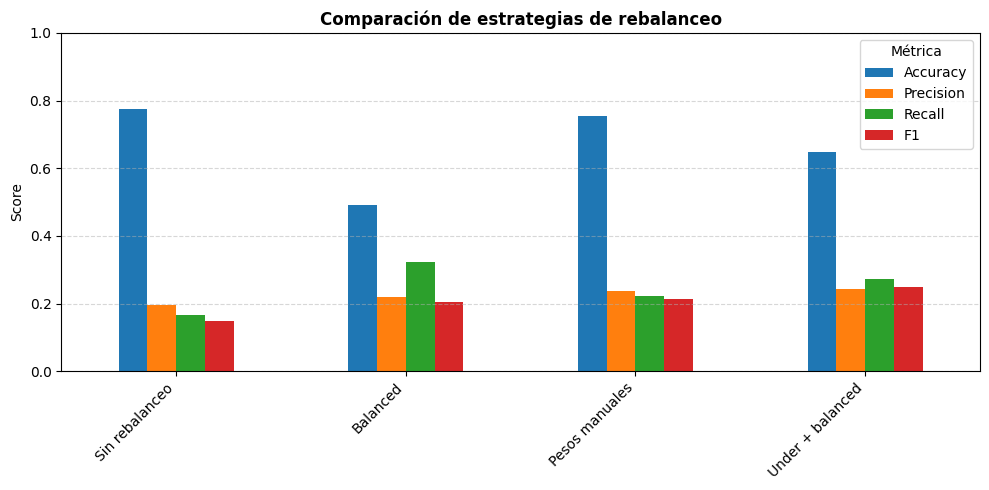

In [179]:
metricas = {"Sin rebalanceo": metricas_val_base, "Balanced": metricas_val_balanced, "Pesos manuales": metricas_val_manual, "Under + balanced": metricas_val_undersampling}
plot_comparacion_metricas(metricas, "Comparación de estrategias de rebalanceo")